# Deteccion de fraude con regresion logistica

En este laboratorio se construye un modelo para clasificar transacciones como legitimas o fraudulentas. Se revisan los datos, se preparan las variables, se entrena el modelo y al final se evaluan sus resultados.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 1. Carga y exploracion de los datos

In [2]:
url = "https://hybridge-education-machine-learning-datasets.s3.us-east-1.amazonaws.com/Fraud.csv"
data_path = Path("Fraud.csv")

if not data_path.exists():
    print("Descargando el conjunto de datos...")
    urlretrieve(url, data_path)

columns = [
    "step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"
]
dtypes = {
    "step": "int16",
    "type": "category",
    "amount": "float32",
    "oldbalanceOrg": "float32",
    "newbalanceOrig": "float32",
    "oldbalanceDest": "float32",
    "newbalanceDest": "float32",
    "isFraud": "int8",
    "isFlaggedFraud": "int8",
}

# Se procesa por bloques para no llenar la memoria con los 6.3 millones de filas.
# Conservamos todos los fraudes y una muestra aleatoria del 2% de operaciones legitimas.
sample_parts = []
type_parts = []
total_rows = 0
total_frauds = 0
missing_values = 0

for chunk_number, chunk in enumerate(
    pd.read_csv(data_path, usecols=columns, dtype=dtypes, chunksize=100_000)
):
    total_rows += len(chunk)
    total_frauds += int(chunk["isFraud"].sum())
    missing_values += int(chunk.isna().sum().sum())

    fraud_rows = chunk[chunk["isFraud"] == 1]
    legit_rows = chunk[chunk["isFraud"] == 0].sample(
        frac=0.02, random_state=RANDOM_STATE + chunk_number
    )
    sample_parts.extend([fraud_rows, legit_rows])
    type_parts.append(
        chunk.groupby("type", observed=True)["isFraud"].agg(["count", "sum"]).reset_index()
    )

df = pd.concat(sample_parts, ignore_index=True).sample(frac=1, random_state=RANDOM_STATE)
print(f"Filas del conjunto original: {total_rows:,}")
print(f"Filas usadas para el modelo: {len(df):,}")
print(f"Columnas utilizadas: {df.shape[1]}")
df.head()

Filas del conjunto original: 6,362,620
Filas usadas para el modelo: 135,296
Columnas utilizadas: 9


In [3]:
legit_total = total_rows - total_frauds
fraud_rate = total_frauds / total_rows * 100

print("Distribucion de la variable objetivo:")
print(f"Transacciones legitimas: {legit_total:,}")
print(f"Transacciones fraudulentas: {total_frauds:,}")
print(f"Porcentaje de fraude: {fraud_rate:.4f}%")
print(f"Valores faltantes: {missing_values}")

Distribucion de la variable objetivo:
Transacciones legitimas: 6,354,407
Transacciones fraudulentas: 8,213
Porcentaje de fraude: 0.1291%
Valores faltantes: 0


In [4]:
fraud_by_type = (
    pd.concat(type_parts, ignore_index=True)
      .groupby("type", observed=True)[["count", "sum"]]
      .sum()
      .rename(columns={"count": "transacciones", "sum": "fraudes"})
      .sort_values("fraudes", ascending=False)
)
fraud_by_type["tasa_fraude"] = fraud_by_type["fraudes"] / fraud_by_type["transacciones"] * 100
fraud_by_type

          transacciones  fraudes  tasa_fraude
type                                           
CASH_OUT       2,237,500     4,116        0.184
TRANSFER         532,909     4,097        0.769
CASH_IN        1,399,284         0        0.000
DEBIT             41,432         0        0.000
PAYMENT        2,151,495         0        0.000

Los datos estan muy desbalanceados: hay muchas mas operaciones legitimas que fraudes. Por eso no conviene evaluar el modelo solamente con exactitud. Tambien se revisaran precision, recall, F1 y ROC-AUC.

## 2. Preparacion de variables

In [5]:
model_df = df.copy()

# Diferencias que ayudan a detectar movimientos inconsistentes de saldo.
model_df["error_saldo_origen"] = (
    model_df["oldbalanceOrg"] - model_df["amount"] - model_df["newbalanceOrig"]
)
model_df["error_saldo_destino"] = (
    model_df["oldbalanceDest"] + model_df["amount"] - model_df["newbalanceDest"]
)

features = [
    "step", "type", "amount", "oldbalanceOrg", "newbalanceOrig",
    "oldbalanceDest", "newbalanceDest", "isFlaggedFraud",
    "error_saldo_origen", "error_saldo_destino"
]
X = model_df[features]
y = model_df["isFraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Entrenamiento: {len(X_train):,} filas ({int(y_train.sum()):,} fraudes)")
print(f"Prueba: {len(X_test):,} filas ({int(y_test.sum()):,} fraudes)")

Entrenamiento: 108,236 filas (6,570 fraudes)
Prueba: 27,060 filas (1,643 fraudes)


## 3. Entrenamiento del modelo

In [6]:
numeric_features = [column for column in features if column != "type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("type", OneHotEncoder(handle_unknown="ignore"), ["type"]),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            solver="liblinear",
            random_state=RANDOM_STATE,
        )),
    ]
)

model.fit(X_train, y_train)
print("Modelo entrenado correctamente")

Modelo entrenado correctamente


## 4. Evaluacion final

In [7]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrics = {
    "Exactitud": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}

print("METRICAS FINALES DEL MODELO")
print("-" * 34)
for name, value in metrics.items():
    print(f"{name:10s}: {value:.4f}")

print("\nMatriz de confusion:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de clasificacion:")
print(classification_report(y_test, y_pred, digits=4))

METRICAS FINALES DEL MODELO
----------------------------------
Exactitud : 0.9511
Precision : 0.5553
Recall    : 0.9805
F1-score  : 0.7091
ROC-AUC   : 0.9945

Matriz de confusion:
[[24127  1290]
 [   32  1611]]

Reporte de clasificacion:
              precision    recall  f1-score   support

           0     0.9987    0.9492    0.9733     25417
           1     0.5553    0.9805    0.7091      1643

    accuracy                         0.9511     27060
   macro avg     0.7770    0.9649    0.8412     27060
weighted avg     0.9718    0.9511    0.9573     27060


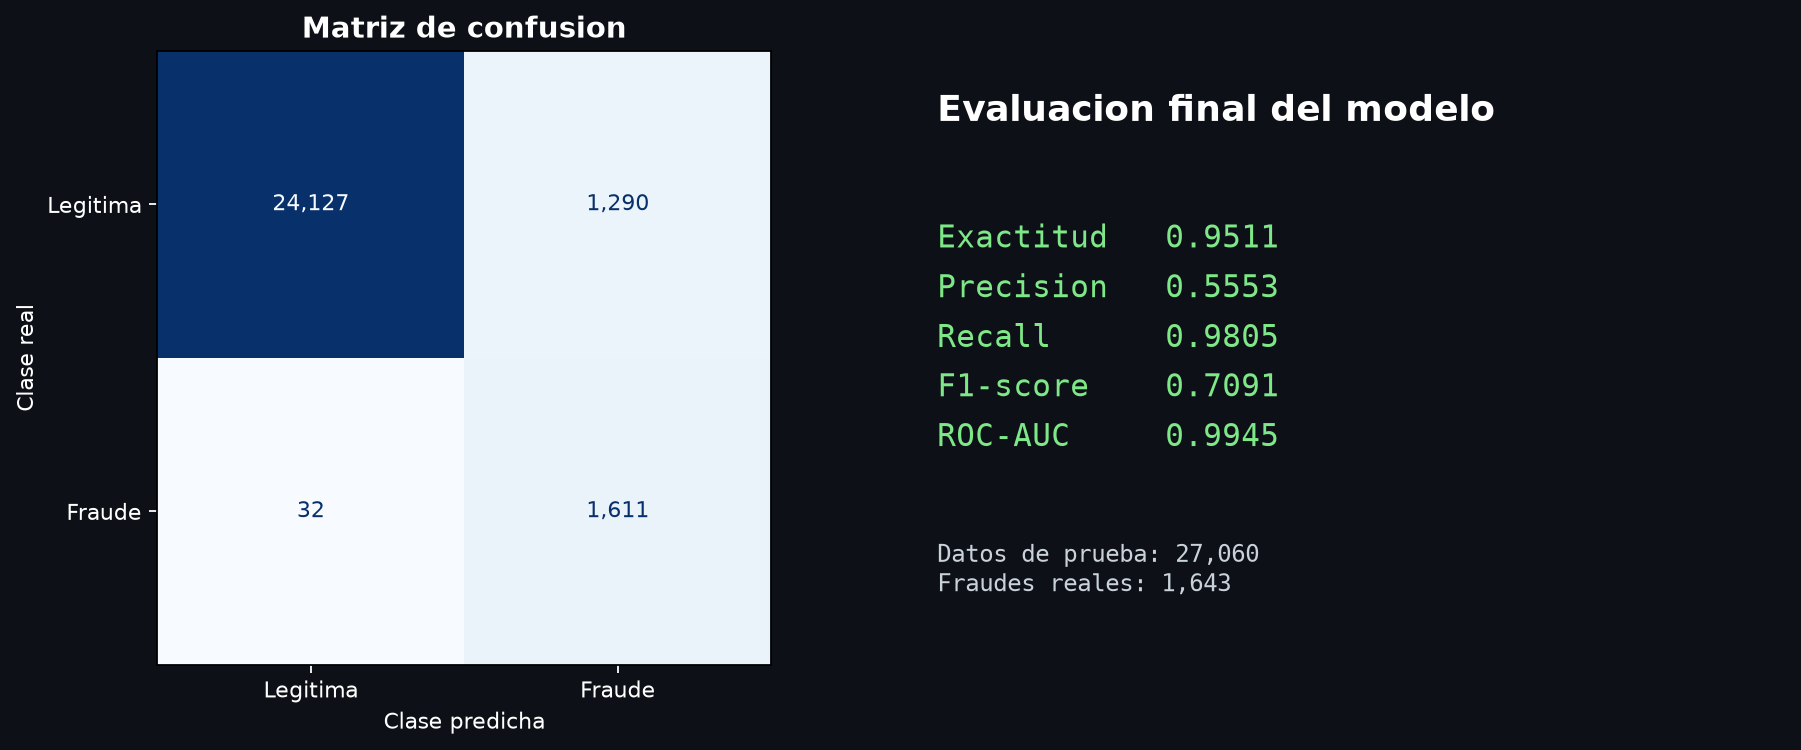

In [8]:
cm = confusion_matrix(y_test, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
fig.patch.set_facecolor("#0d1117")

ConfusionMatrixDisplay(cm, display_labels=["Legitima", "Fraude"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False, values_format=",d"
)
axes[0].set_title("Matriz de confusion", color="white", fontsize=13, weight="bold")
axes[0].set_xlabel("Clase predicha", color="white")
axes[0].set_ylabel("Clase real", color="white")
axes[0].tick_params(colors="white")
axes[0].set_facecolor("#161b22")

axes[1].axis("off")
axes[1].set_facecolor("#0d1117")
axes[1].text(
    0.05, 0.93, "Evaluacion final del modelo", color="white",
    fontsize=16, weight="bold", va="top"
)
metric_text = "\n".join(f"{name:<10}  {value:.4f}" for name, value in metrics.items())
axes[1].text(
    0.05, 0.74, metric_text, color="#7ee787", fontsize=14,
    family="monospace", va="top", linespacing=1.6
)
axes[1].text(
    0.05, 0.12,
    f"Datos de prueba: {len(y_test):,}\nFraudes reales: {int(y_test.sum()):,}",
    color="#c9d1d9", fontsize=11, family="monospace"
)

plt.tight_layout()
plt.savefig("captura_metricas_regresion_logistica.png", dpi=160, facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()

## Conclusion

El modelo logra identificar gran parte de las operaciones fraudulentas. Debido al fuerte desbalance de clases, la precision es menor que el recall: aparecen algunas alertas falsas, pero se reduce el riesgo de dejar pasar fraudes reales. Para este problema el recall es especialmente importante porque un falso negativo representa un fraude no detectado.